In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from arch import arch_model
import yfinance as yf
import scipy.stats as stats

from scipy.stats import jarque_bera
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import adfuller

import warnings
warnings.filterwarnings('ignore')

## DATA EXTRACTION AND PLOTING

In [26]:
crypto_tickers = ["BTC-USD", "BNB-USD", "XRP-USD", "SOL-USD"]
start, end = "2021-01-01", "2026-11-05"

In [27]:
data = yf.download(crypto_tickers, start=start, end=end)

[                       0%                       ]

[*********************100%***********************]  4 of 4 completed


In [28]:
data.to_csv('crypto_dataset.csv')

In [29]:
crypto_data = pd.read_csv('crypto_dataset.csv')

In [30]:
crypto_data.tail()

,Price,Close,Close.1,Close.2,Close.3,High,High.1,High.2,High.3,Low,...,Low.2,Low.3,Open,Open.1,Open.2,Open.3,Volume,Volume.1,Volume.2,Volume.3
2131,2026-10-31,702.6133422851562,77434.75,95.34821319580078,1.2501139640808105,709.1649780273438,77629.7265625,96.85238647460938,1.2595709562301636,698.7128295898438,...,95.15679931640625,1.2415050268173218,703.3541259765625,77198.2109375,96.21875762939453,1.2544089555740356,1102088860,12266900815,1670279662,842045554
2132,2026-11-01,711.8843383789062,78248.453125,94.45462799072266,1.2498639822006226,716.6063232421875,78313.2578125,95.79606628417969,1.256742000579834,701.4757080078125,...,93.20746612548828,1.2427630424499512,702.6133422851562,77434.75,95.34821319580078,1.2501139640808105,1223728132,12716066018,1511668171,890861815
2133,2026-11-02,698.042724609375,76677.296875,91.83545684814453,1.247802972793579,714.7192993164062,78724.390625,95.698974609375,1.2614719867706299,693.4141845703125,...,90.87689971923828,1.2351950407028198,711.8843383789062,78248.453125,94.45462799072266,1.2498639822006226,1347003711,23565885339,2864174723,1549974896
2134,2026-11-03,698.5309448242188,77345.046875,92.91902923583984,1.277325987815857,700.9330444335938,77964.9765625,93.7733383178711,1.285979986190796,690.8468627929688,...,91.21883392333984,1.2451319694519043,698.042724609375,76677.296875,91.83545684814453,1.247802972793579,1199407202,22409398140,2015191202,1690594551
2135,2026-11-04,719.5460815429688,80405.2890625,95.48838806152344,1.3046510219573975,722.6199951171875,81079.7890625,97.69539642333984,1.335260033607483,681.750732421875,...,90.14241790771484,1.2422499656677246,698.5309448242188,77345.046875,92.91902923583984,1.277325987815857,1724981373,40881988659,4160011037,3110389889


In [31]:
crypto_data = pd.read_csv("crypto_dataset.csv", header=[0, 1], index_col=0,
                skiprows=[2], parse_dates=True)["Close"]

In [32]:
crypto_data


Ticker,BNB-USD,BTC-USD,SOL-USD,XRP-USD
2021-01-01,37.905010,29374.152344,1.842084,0.237444
2021-01-02,38.241592,32127.267578,1.799275,0.221655
2021-01-03,41.148979,32782.023438,2.161752,0.225848
2021-01-04,40.926353,31971.914062,2.485097,0.236677
2021-01-05,41.734600,33992.429688,2.157217,0.226750
...,...,...,...,...
2026-10-31,702.613342,77434.750000,95.348213,1.250114
2026-11-01,711.884338,78248.453125,94.454628,1.249864
2026-11-02,698.042725,76677.296875,91.835457,1.247803
2026-11-03,698.530945,77345.046875,92.919029,1.277326


In [33]:
crypto_data = crypto_data.rename_axis(columns=None, index="Date")

In [34]:
crypto_data

,BNB-USD,BTC-USD,SOL-USD,XRP-USD
Date,,,,
2021-01-01,37.905010,29374.152344,1.842084,0.237444
2021-01-02,38.241592,32127.267578,1.799275,0.221655
2021-01-03,41.148979,32782.023438,2.161752,0.225848
2021-01-04,40.926353,31971.914062,2.485097,0.236677
2021-01-05,41.734600,33992.429688,2.157217,0.226750
...,...,...,...,...
2026-10-31,702.613342,77434.750000,95.348213,1.250114
2026-11-01,711.884338,78248.453125,94.454628,1.249864
2026-11-02,698.042725,76677.296875,91.835457,1.247803


In [35]:
crypto_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 2134 entries, 2021-01-01 to 2026-11-04
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BNB-USD  2134 non-null   float64
 1   BTC-USD  2134 non-null   float64
 2   SOL-USD  2134 non-null   float64
 3   XRP-USD  2134 non-null   float64
dtypes: float64(4)
memory usage: 83.4 KB


In [36]:
crypto_data.describe().T

,count,mean,std,min,25%,50%,75%,max
BNB-USD,2134.0,488.315247,221.079135,37.905010,300.445351,502.427811,626.993942,1310.214355
BTC-USD,2134.0,57260.592131,28320.642017,15787.284180,31383.388672,56130.003906,77433.400391,124752.531250
SOL-USD,2134.0,97.691440,66.589134,1.799275,31.939753,92.193386,147.998631,261.869751
XRP-USD,2134.0,1.075847,0.777369,0.221655,0.503956,0.706793,1.408770,3.555765


Calculating the log returns

In [37]:
log_returns = np.log(crypto_data/crypto_data.shift(1)).dropna()

In [38]:
log_returns

,BNB-USD,BTC-USD,SOL-USD,XRP-USD
Date,,,,
2021-01-02,0.008840,0.089590,-0.023514,-0.068810
2021-01-03,0.073275,0.020175,0.183535,0.018740
2021-01-04,-0.005425,-0.025022,0.139393,0.046834
2021-01-05,0.019556,0.061280,-0.141493,-0.042848
2021-01-06,0.010283,0.080022,-0.111705,0.101186
...,...,...,...,...
2026-10-31,-0.001054,0.003059,-0.009089,-0.003430
2026-11-01,0.013109,0.010453,-0.009416,-0.000200
2026-11-02,-0.019635,-0.020283,-0.028121,-0.001650


In [39]:
log_returns.describe().T

,count,mean,std,min,25%,50%,75%,max
BNB-USD,2133.0,0.001380,0.040365,-0.404450,-0.014233,0.001184,0.015368,0.529218
BTC-USD,2133.0,0.000472,0.029656,-0.174053,-0.013219,-0.000047,0.013724,0.171821
SOL-USD,2133.0,0.001851,0.056401,-0.549582,-0.028025,-0.000266,0.028624,0.305299
XRP-USD,2133.0,0.000799,0.049390,-0.396244,-0.019809,-0.000595,0.018300,0.548555


In [40]:
log_returns.skew()

BNB-USD    0.874421
BTC-USD   -0.128482
SOL-USD   -0.360349
XRP-USD    1.253393
dtype: float64

In [41]:
log_returns.kurt()

BNB-USD    24.803995
BTC-USD     4.196010
SOL-USD     9.299338
XRP-USD    17.793568
dtype: float64

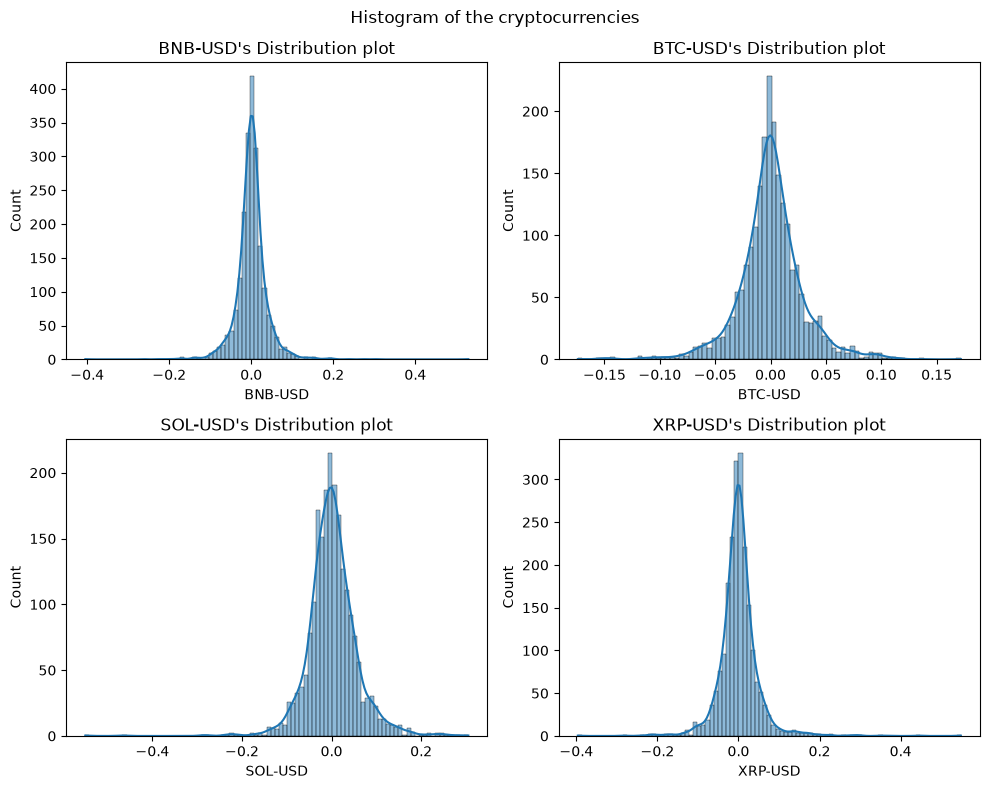

In [42]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10,8))
ax = ax.ravel()
for i, crypto in enumerate(log_returns.columns):
    sns.histplot(log_returns[crypto], kde=True, ax=ax[i])
    ax[i].set_title(f'{crypto}\'s Distribution plot')

plt.suptitle('Histogram of the cryptocurrencies')
plt.tight_layout()
plt.show()

## Jacque-Bera test for normality

**Jarque-Bera test (normality)**

$$H_0: \text{the returns are normally distributed }$$
$$H_1: \text{the returns are not normally distributed}$$

Test statistic:

$$JB = \frac{T}{6}\left(S^2 + \frac{(K-3)^2}{4}\right) \sim \chi^2(2)$$

where $T$ is the number of observations, $S$ is the skewness and $K$ is the kurtosis.

Decision rule: reject $H_0$ if $JB > \chi^2_{2,\,0.95} = 5.99$, or equivalently if the $p$-value $< 0.05$.

In [43]:
stat = pd.DataFrame({
    'skew': log_returns.skew(),
    'excess kurt': log_returns.kurt(),
    'JB p': [jarque_bera(log_returns[c])[1] for c in log_returns.columns],
})
print(stat.round(4))

           skew  excess kurt  JB p
BNB-USD  0.8744      24.8040   0.0
BTC-USD -0.1285       4.1960   0.0
SOL-USD -0.3603       9.2993   0.0
XRP-USD  1.2534      17.7936   0.0


## LOG Returns and Correlation

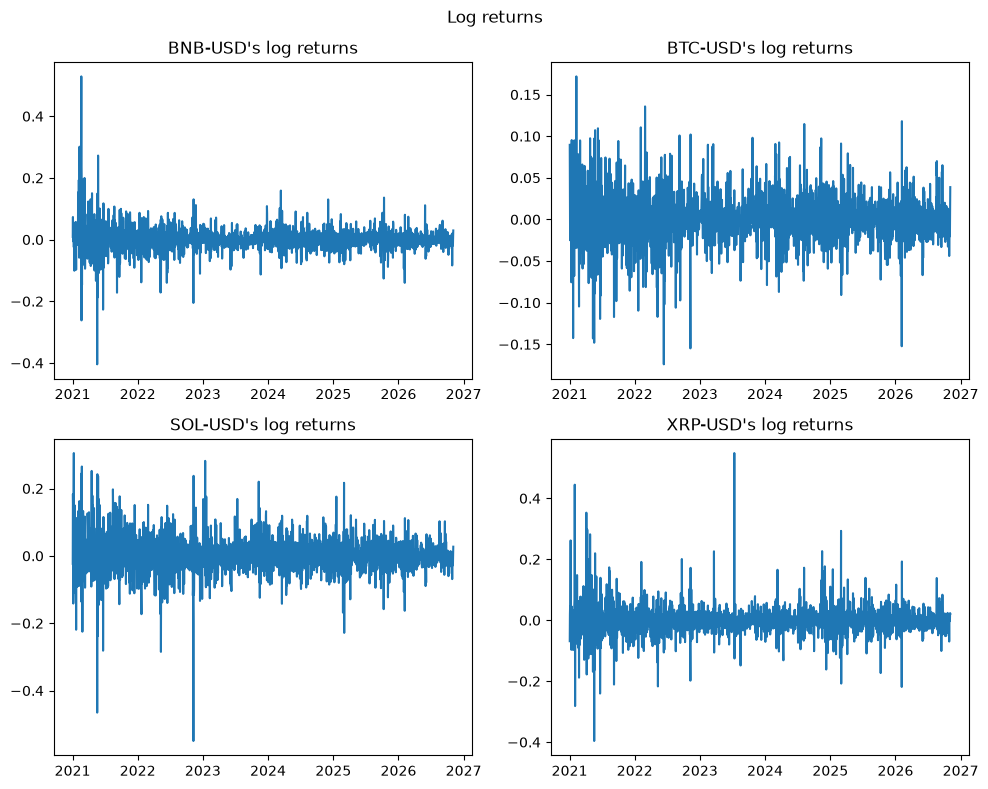

In [44]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10,8))
ax = ax.ravel()

for i, crypto in enumerate(log_returns.columns):
    ax[i].plot(log_returns[crypto])
    ax[i].set_title(f'{crypto}\'s log returns')
# ax[5].
plt.suptitle('Log returns')
plt.tight_layout()
plt.show()

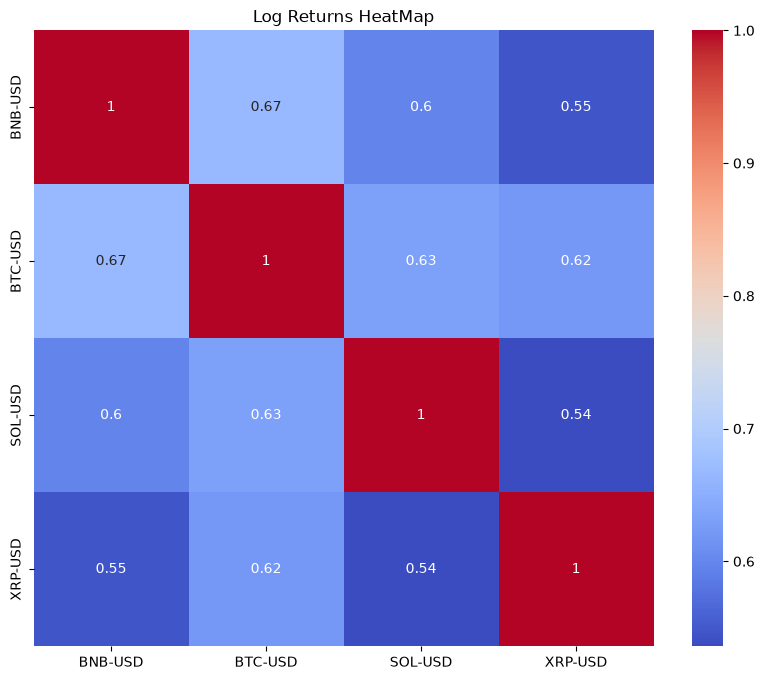

In [45]:
corr_matrix = log_returns.corr()
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Log Returns HeatMap')
plt.show()

## Augmented Dickey-Fuller test for stationarity (ADF)

$$\Delta y_t = \alpha + \beta t + \gamma y_{t-1} + \sum_{i=1}^{p} \delta_i \Delta y_{t-i} + \varepsilon_t$$


*   **Null Hypothesis ($H_0$) :** $\gamma = 0$ $\rightarrow$ The series has a unit root; it is **non stationary**
*   **Alternative Hypothèse($H_1$) :** $\gamma < 0$ $\rightarrow$ The series doesn't have a unit root; it is **stationary**

If the **p-value $\leq 0.05$** (or if the test statistic is less than the critical value), we **reject $H_0$** and conclude that the log returns series is **stationary**.


In [46]:
def adf_test(serie):
    adf_res = adfuller(serie)

    print(f'ADF Statistic >> {adf_res[0]}')
    print(f'ADF proba >> {adf_res[1]}')

    if adf_res[1] <= 0.05:
        print('Stationary')
    else:
        print('Not Stationary')

In [47]:
for crypto in log_returns.columns:
    print(f'---{crypto}---')
    adf_test(log_returns[crypto])
    print('-'*30)


---BNB-USD---
ADF Statistic >> -11.752869998639724
ADF proba >> 1.1975786758448657e-21
Stationary
------------------------------
---BTC-USD---
ADF Statistic >> -47.92388727922561
ADF proba >> 0.0
Stationary
------------------------------
---SOL-USD---
ADF Statistic >> -15.701004537178484
ADF proba >> 1.3961549014453814e-28
Stationary
------------------------------
---XRP-USD---
ADF Statistic >> -12.157044938309179
ADF proba >> 1.5236166114264076e-22
Stationary
------------------------------


## Engle's Test for ARCH Effects (ARCH-LM Test)

Engle’s Lagrange Multiplier (LM) test is used to check for the presence of autoregressive conditional heteroskedasticity (ARCH effects) in the residuals of a stationary series. First, the residuals $e_t$ are estimated (via a mean regression, or simply by de-meaning the returns), and then an autoregressive regression is fitted on the squared residuals:

$$e_t^2 = \alpha_0 + \alpha_1 e_{t-1}^2 + \alpha_2 e_{t-2}^2 + \dots + \alpha_q e_{t-q}^2 + v_t$$

#### Test Hypotheses:
*   **Null Hypothesis ($H_0$):** $\alpha_1 = \alpha_2 = \dots = \alpha_q = 0$ $\rightarrow$ No ARCH effects (volatility is constant over time).
*   **Alternative Hypothesis ($H_1$):** At least one coefficient $\alpha_i \neq 0$ $\rightarrow$ Presence of ARCH effects (volatility changes over time / clustering).

If the **p-value $\leq 0.05$**, we **reject $H_0$** and confirm the presence of significant ARCH effects. This mathematically justifies the use of a GARCH model.


**Calculating residuals**
$$\varepsilon_t = r_t - \mu$$

In [48]:
resid = log_returns - log_returns.mean()
resid

,BNB-USD,BTC-USD,SOL-USD,XRP-USD
Date,,,,
2021-01-02,0.007460,0.089118,-0.025365,-0.069608
2021-01-03,0.071895,0.019703,0.181684,0.017941
2021-01-04,-0.006805,-0.025495,0.137542,0.046035
2021-01-05,0.018176,0.060808,-0.143344,-0.043647
2021-01-06,0.008903,0.079550,-0.113556,0.100388
...,...,...,...,...
2026-10-31,-0.002434,0.002587,-0.010940,-0.004229
2026-11-01,0.011729,0.009981,-0.011267,-0.000999
2026-11-02,-0.021015,-0.020755,-0.029972,-0.002449


this is a way to determine the number of lags to use in the arch lm test, using the pacf on the squared errors

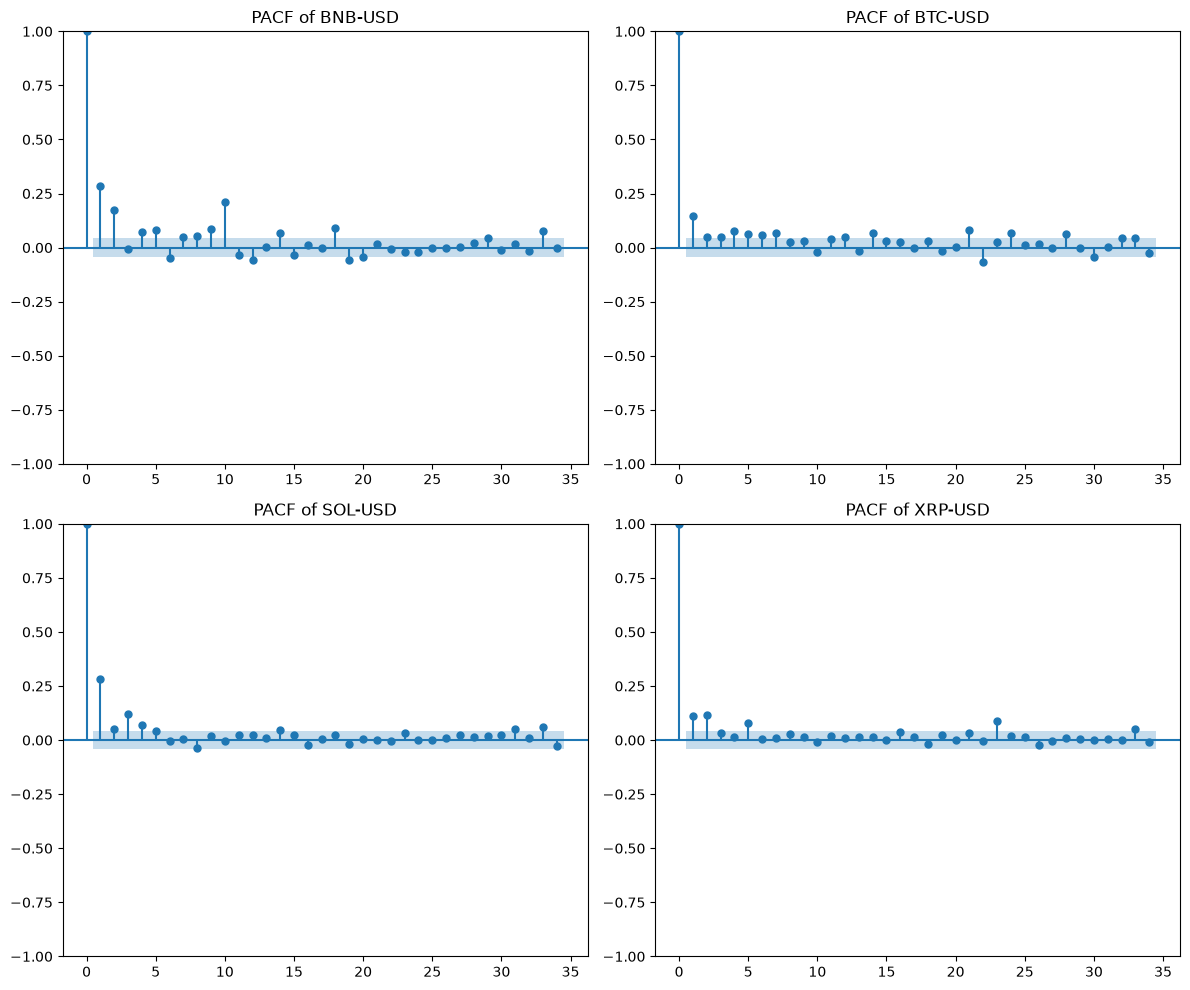

In [49]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12,10))
ax = ax.ravel()
for i, crypto in enumerate(log_returns.columns):
    plot_pacf(resid[crypto]**2, ax=ax[i])
    ax[i].set_title(f'PACF of {crypto}')
plt.tight_layout()
plt.show()

In [50]:
for crypto in resid.columns:
    print(f'---ARCH-LM for {crypto}---')
    lm_stat, lm_proba, f_stat, f_proba = arch_lm_test = het_arch(resid[crypto], nlags=7)
    print(f'LM_STAT >> {lm_stat}')
    print(f'LM_PROBA >> {lm_proba}')

    if lm_proba <= 0.05:
        print("reject H0(presence of ARCH effects)")
    else:
        print('Fail to reject H0(volatility is constant)')
    print('-'*30)

---ARCH-LM for BNB-USD---
LM_STAT >> 261.14148826418807
LM_PROBA >> 1.1754809640929024e-52
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for BTC-USD---
LM_STAT >> 90.18105322399617
LM_PROBA >> 1.1357217999576726e-16
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for SOL-USD---
LM_STAT >> 196.39323396776345
LM_PROBA >> 6.660396286038827e-39
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for XRP-USD---
LM_STAT >> 71.33958280393752
LM_PROBA >> 7.917934118925046e-13
reject H0(presence of ARCH effects)
------------------------------


## Model Construction
**General view of ARCH(q), GARCH(p) and GJR-GARCH(p,q)**

**ARCH(q)**
$$r_t = \mu + \varepsilon_t, \quad \varepsilon_t = \sigma_t z_t, \quad z_t \sim \mathcal{N}(0,1)$$
$$\sigma_t^2 = \alpha_0 + \sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2$$

**GARCH(p,q)**

$$\sigma_t^2 = \alpha_0 + \sum_{i=1}^{q} \alpha_i \varepsilon_{t-i}^2 + \sum_{j=1}^{p} \beta_j \sigma_{t-j}^2$$

Subject to $\alpha_0 > 0,\ \alpha_i \geq 0,\ \beta_j \geq 0$ and $\sum \alpha_i + \sum \beta_j < 1$.

**GJR-GARCH(p,q)**
\begin{equation}
\sigma_t^2 = \omega + (\alpha + \gamma I_{t-1}) \varepsilon_{t-1}^2 + \beta \sigma_{t-1}^2
\end{equation}

where the indicator function is defined as:
\begin{equation}
I_{t-1} = 
\begin{cases} 
1 & \text{if } \varepsilon_{t-1} < 0 \\
0 & \text{if } \varepsilon_{t-1} \ge 0 
\end{cases}
\end{equation}

{Parameter Constraints:}
\begin{equation}
\omega > 0, \quad \alpha \ge 0, \quad \beta \ge 0, \quad \text{and} \quad \alpha + \gamma \ge 0
\end{equation}

In [51]:
garch_result = {}
lr_pct = log_returns * 100
for crypto in lr_pct.columns:

    print(f'===GARCH MODEL ESTIMATION FOR {crypto}===')
    garch_model = arch_model(lr_pct[crypto], mean='constant', vol='GARCH', p=1,q=1, dist='t')
    result_garch = garch_model.fit(disp='off')
    garch_result[crypto] = result_garch
    
    print(f"-> GARCH Classic AIC: {result_garch.aic:.2f}  | BIC: {result_garch.bic:.2f}")
    print('-'*30)
    print(result_garch.summary())

===GARCH MODEL ESTIMATION FOR BNB-USD===
-> GARCH Classic AIC: 10614.80  | BIC: 10643.13
------------------------------
                        Constant Mean - GARCH Model Results                         
Dep. Variable:                      BNB-USD   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5302.40
Distribution:      Standardized Student's t   AIC:                           10614.8
Method:                  Maximum Likelihood   BIC:                           10643.1
                                              No. Observations:                 2133
Date:                      Wed, Nov 11 2026   Df Residuals:                     2132
Time:                              12:23:47   Df Model:                            1
                                 Mean Model                                
                 coef    std err       

In [52]:
GJRGarch_result = {}
for crypto in lr_pct.columns:
    print(f'===GJR-GARCH MODEL ESTIMATION FOR {crypto}===')
    gjr_garch_model = arch_model(lr_pct[crypto], mean='constant', vol='GARCH', p=1,o=1,q=1, dist='studentst')
    result_gjrgarch = gjr_garch_model.fit(disp='off')
    GJRGarch_result[crypto] = result_gjrgarch

    print(f"-> GJR-GARCH     AIC: {result_gjrgarch.aic:.2f} | BIC: {result_gjrgarch.bic:.2f}")
    print('-'*30)
    print(result_gjrgarch.summary())

===GJR-GARCH MODEL ESTIMATION FOR BNB-USD===
-> GJR-GARCH     AIC: 10616.46 | BIC: 10650.45
------------------------------
                      Constant Mean - GJR-GARCH Model Results                       
Dep. Variable:                      BNB-USD   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                        GJR-GARCH   Log-Likelihood:               -5302.23
Distribution:      Standardized Student's t   AIC:                           10616.5
Method:                  Maximum Likelihood   BIC:                           10650.4
                                              No. Observations:                 2133
Date:                      Wed, Nov 11 2026   Df Residuals:                     2132
Time:                              12:23:47   Df Model:                            1
                                 Mean Model                                
                 coef    std err    

Having AIC/BIC compared for both models

I choosed GARCH

selecting the model that has a lower AIC/BIC and that successfully and simply explains the data without unnecessary parameters.

## ARCH-LM test for GARCH'S residuals

In [53]:
for crypto in lr_pct.columns:
    print(f'---ARCH-LM for {crypto}---')
    std_resid = garch_result[crypto].resid / garch_result[crypto].conditional_volatility
    std_resid = std_resid.dropna()
    lm_stat, lm_proba, f_stat, f_proba = arch_lm_test = het_arch(std_resid, nlags=7)
    print(f'LM_STAT >> {lm_stat}')
    print(f'LM_PROBA >> {lm_proba}')

    if lm_proba <= 0.05:
        print("reject H0(presence of ARCH effects)")
    else:
        print('Fail to reject H0(volatility is constant)')
    print('-'*30)

---ARCH-LM for BNB-USD---
LM_STAT >> 2.540809122043627
LM_PROBA >> 0.9239928754385065
Fail to reject H0(volatility is constant)
------------------------------
---ARCH-LM for BTC-USD---
LM_STAT >> 27.519039601040745
LM_PROBA >> 0.00026867275887309996
reject H0(presence of ARCH effects)
------------------------------
---ARCH-LM for SOL-USD---
LM_STAT >> 12.226702337952242
LM_PROBA >> 0.09334581567164091
Fail to reject H0(volatility is constant)
------------------------------
---ARCH-LM for XRP-USD---
LM_STAT >> 0.2830675101300686
LM_PROBA >> 0.9999178333221722
Fail to reject H0(volatility is constant)
------------------------------


Arch effect is not present in all currencies except BTC, this can be explained due to the fact that the btc experienced violent, 

historic volatilty and a single-lag model (1,1) sometimes struggles to absorb 100% of this memory on its own but it's the standard model that is widely used

the fact that there is at least one currencie that conserves the arch effect doesn't make it a failure

especially that it's bitcoin, a currency that have a longer volatility memory.

(also as it'll be presented in the md file, this is for a project not a real institutional model that'll be used.)

### Monte Carlo Value at Risk ($\text{VaR}_{95\%}$)

The Monte Carlo VaR is calculated empirically by simulating $M$ potential future return paths based on a specified probability distribution model (non-GBM), sorting the simulated terminal returns, and extracting the $5^{\text{th}}$ percentile:

$$\text{VaR}_{95\%} = -\text{Percentile}\left(\{\hat{R}_1, \hat{R}_2, \dots, \hat{R}_M\}, 5\right)$$

Where:
* $\hat{R}_j$ is the simulated terminal return for the $j^{\text{th}}$ artificial scenario or path.
* $M$ is the total number of simulated scenarios generated by the model (e.g., $M = 10,000$).
* $\text{Percentile}(\cdot, 5)$ extracts the boundary value below which the worst $5\%$ of simulated outcomes fall.


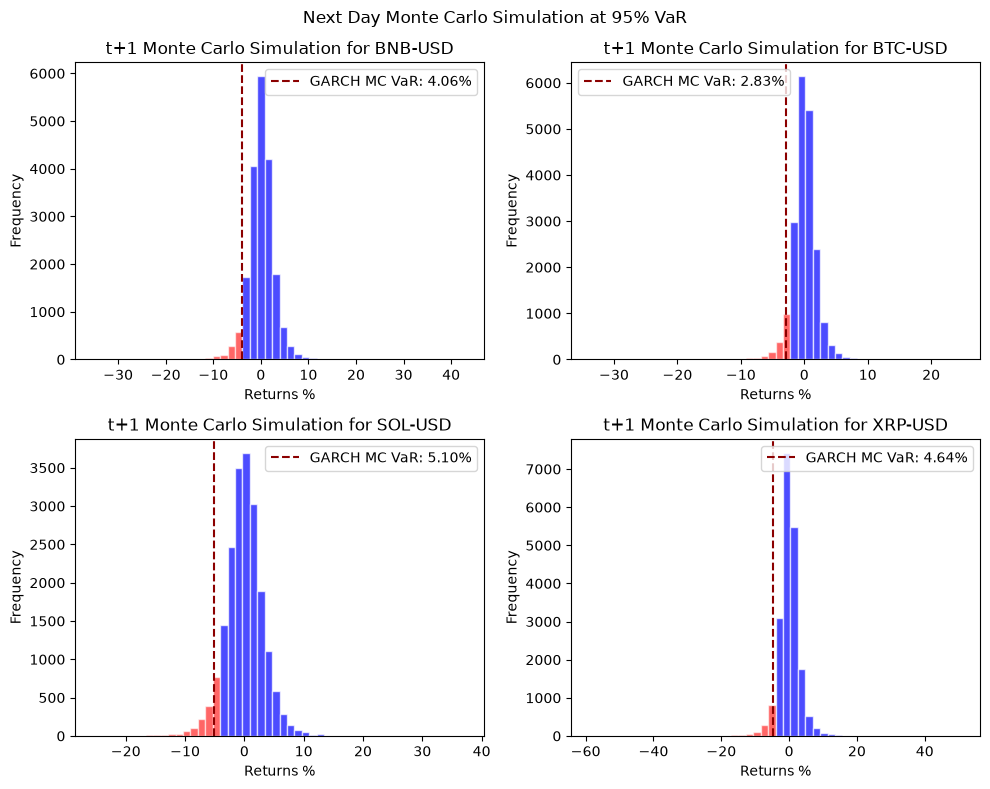

=== Next-Day 1-Day 95% GARCH-Monte Carlo VaR ===
BNB-USD: 4.06%
BTC-USD: 2.83%
SOL-USD: 5.10%
XRP-USD: 4.64%


In [54]:
#Monte Carlo Construction
Simulations = 20000
confidence_interval = 0.95
alpha = (1-confidence_interval) * 100

monte_carlo_results = {}

fi,ax = plt.subplots(nrows=2,ncols=2, figsize=(10,8))
ax = ax.ravel()

for i,crypto in enumerate(lr_pct.columns):
    mu = garch_result[crypto].params['mu']
    nu = garch_result[crypto].params['nu']
    vol = garch_result[crypto].conditional_volatility.iloc[-1]

    np.random.seed(42)
    standardized_shocks = stats.t.rvs(df=nu, loc=0, scale=1,size=Simulations)
    rescaled_shocks = standardized_shocks / np.sqrt(nu/(nu-2))

    simulated_returns = mu + vol * rescaled_shocks

    var_threshold = np.percentile(simulated_returns, alpha)
    monte_carlo_results[crypto] = -var_threshold

    count,bins,patches = ax[i].hist(simulated_returns, bins=50, edgecolor='white', color='blue', alpha=0.7)

    for patch in patches:
        if patch.get_x() < var_threshold:
            patch.set_facecolor('red')
            patch.set_alpha(0.6)
    

#Monte Carlo ploting

    ax[i].axvline(var_threshold, color='darkred', linestyle='--', label=f"GARCH MC VaR: {abs(var_threshold):.2f}%")
    ax[i].set_title(f't+1 Monte Carlo Simulation for {crypto}')
    ax[i].set_xlabel('Returns %')
    ax[i].set_ylabel('Frequency')
    ax[i].legend()
plt.suptitle('Next Day Monte Carlo Simulation at 95% VaR')
plt.tight_layout()
plt.show()
print("=== Next-Day 1-Day 95% GARCH-Monte Carlo VaR ===")
for crypto, var_val in monte_carlo_results.items():
    print(f"{crypto}: {var_val:.2f}%")

## Portfolio Construction

In [55]:
weights = np.ones(4)/4

In [56]:
port_log_returns = log_returns @ weights
pct_port = port_log_returns * 100
pct_port

Date
2021-01-02    0.152675
2021-01-03    7.393146
2021-01-04    3.894485
2021-01-05   -2.587616
2021-01-06    1.994652
                ...   
2026-10-31   -0.262823
2026-11-01    0.348654
2026-11-02   -1.742250
2026-11-03    1.112112
2026-11-04    2.922187
Length: 2133, dtype: float64

In [57]:
GARCH_portfolio = arch_model(pct_port, mean='constant', vol='GARCH',p=1,q=1, dist='t').fit(disp='off')
GARCH_portfolio

                        Constant Mean - GARCH Model Results                         
Dep. Variable:                         None   R-squared:                       0.000
Mean Model:                   Constant Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -5448.56
Distribution:      Standardized Student's t   AIC:                           10907.1
Method:                  Maximum Likelihood   BIC:                           10935.4
                                              No. Observations:                 2133
Date:                      Wed, Nov 11 2026   Df Residuals:                     2132
Time:                              12:23:49   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu        

In [58]:
resid_portfolio = GARCH_portfolio.resid
std_resid_portfolio = resid_portfolio / GARCH_portfolio.conditional_volatility
lm_stat, lm_proba, f_stat, f_proba = arch_lm_test = het_arch(std_resid_portfolio, nlags=7)
print(f'LM_STAT >> {lm_stat}')
print(f'LM_PROBA >> {lm_proba}')

if lm_proba <= 0.05:
    print("reject H0(presence of ARCH effects)")
else:
    print('Fail to reject H0(volatility is constant)')

LM_STAT >> 3.250081458376366
LM_PROBA >> 0.8609443312763397
Fail to reject H0(volatility is constant)


In [59]:
forecasts = GARCH_portfolio.forecast(horizon=10)

variance_forecast = forecasts.variance.iloc[-1]
print(variance_forecast)

h.01    7.523920
h.02    7.843517
h.03    8.149199
h.04    8.441572
h.05    8.721214
h.06    8.988681
h.07    9.244502
h.08    9.489184
h.09    9.723213
h.10    9.947052
Name: 2026-11-04 00:00:00, dtype: float64


Portfolio 95% Monte Carlo VaR: 4.64%


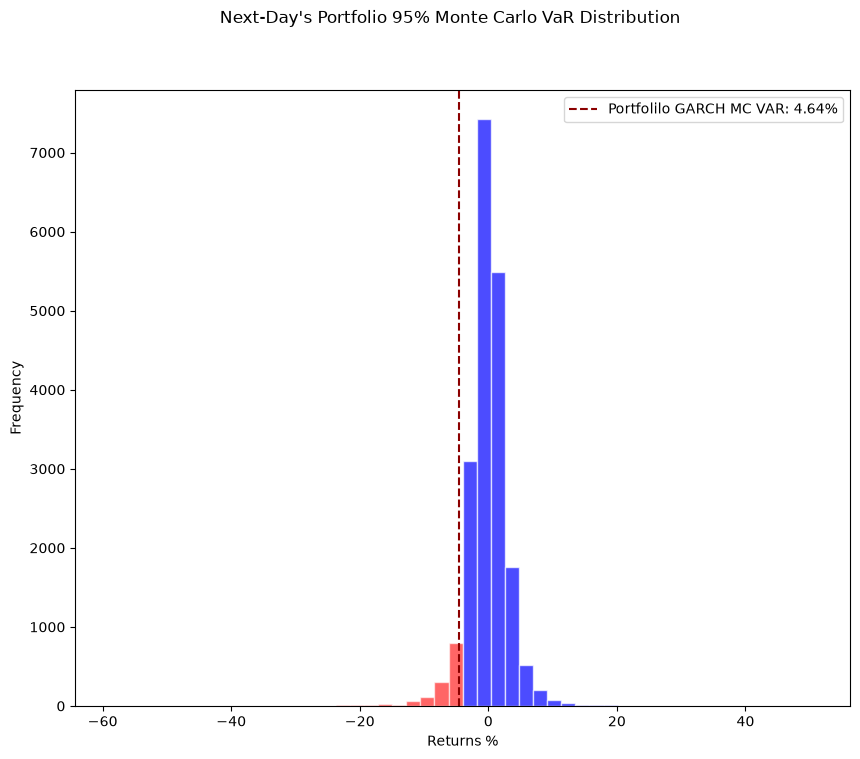

In [70]:
simulations = 20000
confidence_interval = 0.95
alpha = (1-confidence_interval)*100
portfolio_mc_results = {}

mu_p = GARCH_portfolio.params['mu']
nu_p = GARCH_portfolio.params['nu']
vol_p = GARCH_portfolio.conditional_volatility.iloc[-1]

np.random.seed(42)
standardized_shocks = stats.t.rvs(df=nu_p, loc=0, scale=1,size=simulations)
rescaled_shocks = standardized_shocks / np.sqrt(nu_p/nu_p-2)

simulation_returns = mu_p + vol_p * rescaled_shocks

port_var_threshold = np.percentile(simulated_returns, alpha)
portfolio_mc_results = -port_var_threshold

plt.figure(figsize=(10,8))
count, bins, patches = plt.hist(simulated_returns, bins=50, edgecolor='white', color='blue', alpha=0.7)

for patch in patches:
    if patch.get_x() < port_var_threshold:
        patch.set_facecolor('red')
        patch.set_alpha(0.6)

plt.axvline(port_var_threshold, color='darkred', linestyle='--', label=f'Portfolilo GARCH MC VAR: {abs(var_threshold):.2f}%')
plt.xlabel('Returns %')
plt.ylabel('Frequency')
plt.legend()
plt.suptitle("Next-Day's Portfolio 95% Monte Carlo VaR Distribution")
print(f"Portfolio 95% Monte Carlo VaR: {abs(port_var_threshold):.2f}%")
